In [1]:
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import plot_model
from tensorflow.keras.layers import Flatten, Dense
import matplotlib.pyplot as plt
from sklearn.metrics import plot_confusion_matrix, ConfusionMatrixDisplay, confusion_matrix
import seaborn as sns
import numpy as np

In [2]:
# Load the Fashion MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

In [3]:
# Create the dictionaries for unsupervised and supervised learning
unsupervised_AnkitPatil = {'images': x_train}
supervised_AnkitPatil = {'images': x_test, 'labels': y_test}

In [4]:
# Data Pre-processing 

# Normalize the pixel values to a range between 0-1
unsupervised_AnkitPatil['images'] = unsupervised_AnkitPatil['images'].astype('float32') / 255.0
supervised_AnkitPatil['images'] = supervised_AnkitPatil['images'].astype('float32') / 255.0

In [5]:
supervised_AnkitPatil['labels'] = tf.keras.utils.to_categorical(supervised_AnkitPatil['labels'],10)

In [6]:
# Print the shape of the data
print("Shape of unsupervised_AnkitPatil['images']:", unsupervised_AnkitPatil['images'].shape)
print("Shape of supervised_AnkitPatil['images']:", supervised_AnkitPatil['images'].shape)
print("Shape of supervised_AnkitPatil['labels']:", supervised_AnkitPatil['labels'].shape)

Shape of unsupervised_AnkitPatil['images']: (60000, 28, 28)
Shape of supervised_AnkitPatil['images']: (10000, 28, 28)
Shape of supervised_AnkitPatil['labels']: (10000, 10)


In [60]:
#Data Preparation
random_seed = 44
# Split the unsupervised data into training (57,000) and validation (3,000) sets
unsupervised_train_AnkitPatil, unsupervised_val_AnkitPatil = train_test_split(unsupervised_AnkitPatil['images'], test_size=0.05, random_state=random_seed)

In [9]:
# Remove 7,000 samples from the supervised dataset
supervised_AnkitPatil['images'], _, supervised_AnkitPatil['labels'], _ = train_test_split(supervised_AnkitPatil['images'], supervised_AnkitPatil['labels'], test_size=0.70, random_state=random_seed)

In [10]:
# Split the remaining supervised dataset into training, validation, and testing sets
x_train_AnkitPatil, x_test_AnkitPatil, y_train_AnkitPatil, y_test_AnkitPatil = train_test_split(supervised_AnkitPatil['images'], supervised_AnkitPatil['labels'], test_size=0.2, random_state=random_seed)

x_train_AnkitPatil, x_val_AnkitPatil, y_train_AnkitPatil, y_val_AnkitPatil = train_test_split(x_train_AnkitPatil, y_train_AnkitPatil, test_size=0.25, random_state=random_seed)

In [12]:
# Print the shapes of the dataframes
print("Shape of unsupervised_train_Ankit:", unsupervised_train_AnkitPatil.shape)
print("Shape of unsupervised_val_Ankit:", unsupervised_val_AnkitPatil.shape)
print("Shape of x_train_Ankit:", x_train_AnkitPatil.shape)
print("Shape of x_val_Ankit:", x_val_AnkitPatil.shape)
print("Shape of x_test_Ankit:", x_test_AnkitPatil.shape)
print("Shape of y_train_Ankit:", y_train_AnkitPatil.shape)
print("Shape of y_val_Ankit:", y_val_AnkitPatil.shape)
print("Shape of y_test_Ankit:", y_test_AnkitPatil.shape)

Shape of unsupervised_train_Ankit: (57000, 28, 28)
Shape of unsupervised_val_Ankit: (3000, 28, 28)
Shape of x_train_Ankit: (1800, 28, 28)
Shape of x_val_Ankit: (600, 28, 28)
Shape of x_test_Ankit: (600, 28, 28)
Shape of y_train_Ankit: (1800, 10)
Shape of y_val_Ankit: (600, 10)
Shape of y_test_Ankit: (600, 10)


In [13]:
# Build, Train, and Validate a baseline CNN Model

# Define the model
cnn_v1_model_AnkitPatil = tf.keras.models.Sequential([
    # Convolutional layer 1
    tf.keras.layers.Conv2D(16, (3,3), activation='relu', padding='same', strides=2, input_shape=(28,28,1)),
    # Convolutional layer 2
    tf.keras.layers.Conv2D(8, (3,3), activation='relu', padding='same', strides=2),
    # Flatten layer
    tf.keras.layers.Flatten(),
    # Fully connected layer
    tf.keras.layers.Dense(100, activation='relu'),
    # Output layer
    tf.keras.layers.Dense(10, activation='softmax')
])


In [14]:
# Compile the model
cnn_v1_model_AnkitPatil.compile(optimizer='adam',
                               loss='categorical_crossentropy',
                               metrics=['accuracy'])

In [15]:
# Display the model summary
cnn_v1_model_AnkitPatil.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 14, 14, 16)        160       
                                                                 
 conv2d_1 (Conv2D)           (None, 7, 7, 8)           1160      
                                                                 
 flatten (Flatten)           (None, 392)               0         
                                                                 
 dense (Dense)               (None, 100)               39300     
                                                                 
 dense_1 (Dense)             (None, 10)                1010      
                                                                 
Total params: 41,630
Trainable params: 41,630
Non-trainable params: 0
_________________________________________________________________


In [16]:
plot_model(cnn_v1_model_AnkitPatil, to_file='cnn_model_Ankit.png', show_shapes=True)

You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) for plot_model to work.


In [17]:
# Fit the model
cnn_v1_history_AnkitPatil = cnn_v1_model_AnkitPatil.fit(x_train_AnkitPatil,
                                                      y_train_AnkitPatil,
                                                      batch_size=256,
                                                      epochs=10,
                                                      validation_data=(x_val_AnkitPatil, y_val_AnkitPatil))

Epoch 1/10
8/8 [==============================] - 1s 73ms/step - loss: 2.2219 - accuracy: 0.2489 - val_loss: 2.0754 - val_accuracy: 0.3917
Epoch 2/10
8/8 [==============================] - 0s 25ms/step - loss: 1.9547 - accuracy: 0.4511 - val_loss: 1.7363 - val_accuracy: 0.5267
Epoch 3/10
8/8 [==============================] - 0s 25ms/step - loss: 1.5716 - accuracy: 0.5456 - val_loss: 1.3220 - val_accuracy: 0.6100
Epoch 4/10
8/8 [==============================] - 0s 25ms/step - loss: 1.1676 - accuracy: 0.6594 - val_loss: 1.0145 - val_accuracy: 0.6667
Epoch 5/10
8/8 [==============================] - 0s 25ms/step - loss: 0.9229 - accuracy: 0.6867 - val_loss: 0.8615 - val_accuracy: 0.7167
Epoch 6/10
8/8 [==============================] - 0s 25ms/step - loss: 0.8385 - accuracy: 0.7111 - val_loss: 0.7952 - val_accuracy: 0.7283
Epoch 7/10
8/8 [==============================] - 0s 46ms/step - loss: 0.7429 - accuracy: 0.7428 - val_loss: 0.7665 - val_accuracy: 0.7450
Epoch 8/10
8/8 [===========

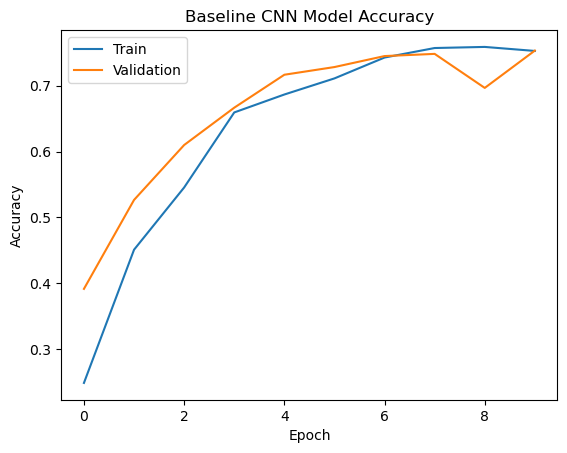

In [18]:
# Plot training & validation accuracy values
plt.plot(cnn_v1_history_AnkitPatil.history['accuracy'])
plt.plot(cnn_v1_history_AnkitPatil.history['val_accuracy'])
plt.title('Baseline CNN Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [19]:
test_loss, test_acc = cnn_v1_model_AnkitPatil.evaluate(x_test_AnkitPatil, y_test_AnkitPatil, verbose=0)
print('Test accuracy:', test_acc)

Test accuracy: 0.7316666841506958


In [21]:
cnn_predictions_AnkitPatil = cnn_v1_model_AnkitPatil.predict(x_test_AnkitPatil)
y_pred = np.argmax(cnn_predictions_AnkitPatil, axis=1)
rounded_labels = np.argmax(y_test_AnkitPatil, axis=1)

19/19 [==============================] - 0s 3ms/step


In [22]:
# Confusion matrix using matplotlib
class_labels = [0,1,2,3,4,5,6,7,8,9]

In [24]:
#Confusion matrix
cm=confusion_matrix(y_pred,rounded_labels)
cm

array([[38,  0,  2,  2,  0,  0, 16,  0,  0,  0],
       [ 0, 45,  0,  0,  0,  0,  0,  0,  0,  0],
       [ 0,  1, 33,  1,  5,  0, 16,  0,  0,  0],
       [ 5,  3,  1, 55,  9,  0,  4,  0,  4,  0],
       [ 0,  1, 23,  3, 46,  0, 18,  0,  0,  0],
       [ 1,  0,  0,  0,  0, 47,  1,  5,  1,  0],
       [ 3,  0,  5,  0,  3,  0,  6,  0,  0,  0],
       [ 0,  0,  0,  0,  0,  3,  0, 43,  0,  1],
       [ 1,  0,  2,  0,  1,  1,  4,  0, 57,  0],
       [ 0,  0,  0,  0,  0,  8,  0,  7,  0, 69]], dtype=int64)

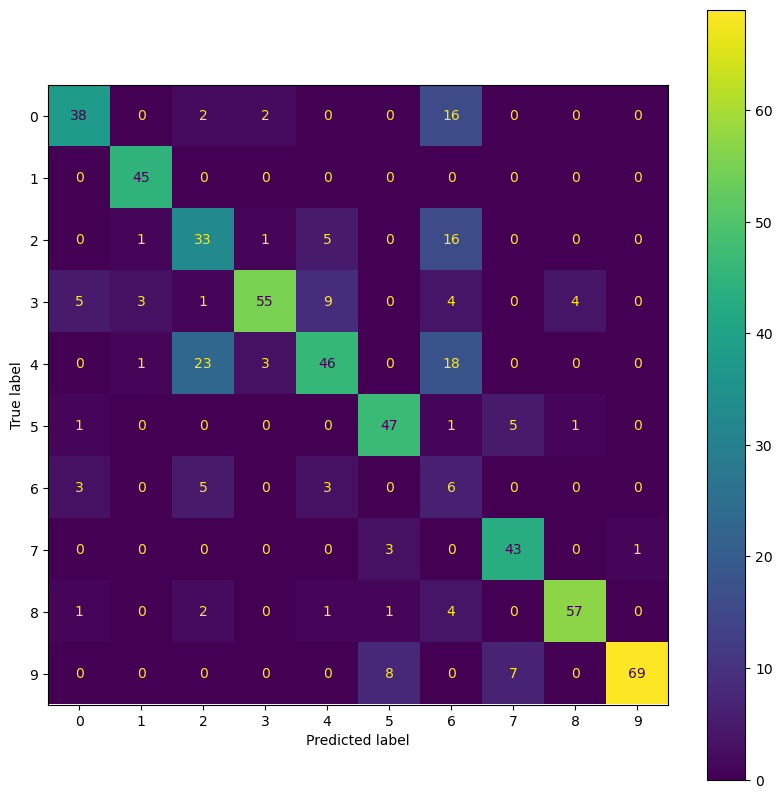

In [25]:
#Plot
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_labels)
fig, ax = plt.subplots(figsize=(10,10))
disp.plot(ax=ax);

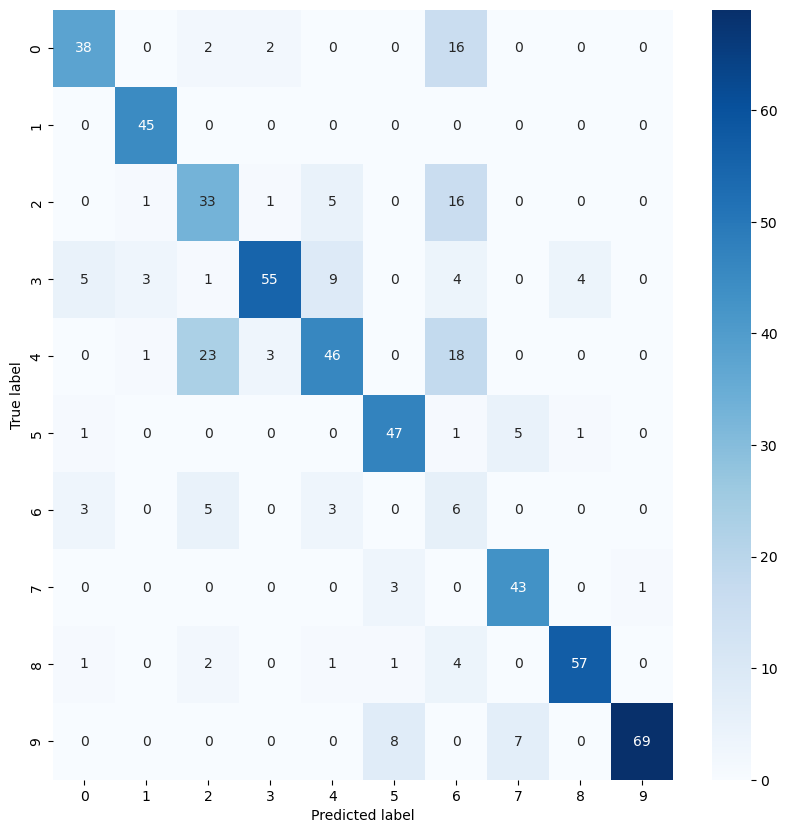

In [26]:
# Plot with Seaborn
plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='g', xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.show()

In [27]:
# Set the random seed to be the last two digits of your student ID number.
tf.random.set_seed(16)

In [28]:
# Add noise to the training and validation datasets
noise_factor = 0.2
x_train_noisy_AnkitPatil = unsupervised_train_AnkitPatil + noise_factor * tf.random.normal(shape=unsupervised_train_AnkitPatil.shape)
x_val_noisy_AnkitPatil = unsupervised_val_AnkitPatil + noise_factor * tf.random.normal(shape=unsupervised_val_AnkitPatil.shape)

In [29]:
# Clip the values of the noisy dataset to be between 0 and 1
x_train_noisy_AnkitPatil = tf.clip_by_value(x_train_noisy_AnkitPatil, clip_value_min=0.0, clip_value_max=1.0)
x_val_noisy_AnkitPatil = tf.clip_by_value(x_val_noisy_AnkitPatil, clip_value_min=0.0, clip_value_max=1.0)

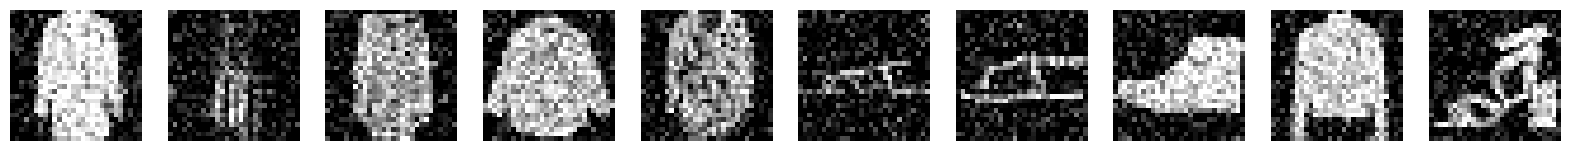

In [30]:
# Display the first 10 images from the noisy validation dataset
fig, ax = plt.subplots(1, 10, figsize=(20, 10))
for i in range(10):
    ax[i].imshow(x_val_noisy_AnkitPatil[i], cmap='gray')
    ax[i].axis('off')
plt.show()

In [31]:
# Set the input shape based on the image size of the Fashion MNIST dataset
input_shape = (28, 28, 1)

In [33]:
# Define the input layer
inputs_AnkitPatil = tf.keras.Input(shape=input_shape)

In [34]:
# Encoder Section
e_AnkitPatil = tf.keras.layers.Conv2D(16, (3, 3), activation='relu', padding='same', strides=2)(inputs_AnkitPatil)
e_AnkitPatil = tf.keras.layers.Conv2D(8, (3, 3), activation='relu', padding='same', strides=2)(e_AnkitPatil)

In [35]:
# Decoder Section
d_AnkitPatil = tf.keras.layers.Conv2DTranspose(8, (3, 3), activation='relu', padding='same', strides=2)(e_AnkitPatil)
d_AnkitPatil = tf.keras.layers.Conv2DTranspose(16, (3, 3), activation='relu', padding='same', strides=2)(d_AnkitPatil)
d_AnkitPatil = tf.keras.layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same')(d_AnkitPatil)

In [36]:
# Define the autoencoder model
autoencoder_AnkitPatil = tf.keras.Model(inputs=inputs_AnkitPatil, outputs=d_AnkitPatil, name='autoencoder_AnkitPatil')

In [37]:
# Compile the autoencoder model
autoencoder_AnkitPatil.compile(optimizer='adam', loss='mean_squared_error')

In [38]:
# Print a summary of the autoencoder model
autoencoder_AnkitPatil.summary()

Model: "autoencoder_AnkitPatil"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 28, 28, 1)]       0         
                                                                 
 conv2d_2 (Conv2D)           (None, 14, 14, 16)        160       
                                                                 
 conv2d_3 (Conv2D)           (None, 7, 7, 8)           1160      
                                                                 
 conv2d_transpose (Conv2DTra  (None, 14, 14, 8)        584       
 nspose)                                                         
                                                                 
 conv2d_transpose_1 (Conv2DT  (None, 28, 28, 16)       1168      
 ranspose)                                                       
                                                                 
 conv2d_4 (Conv2D)           (None, 28, 28, 

In [39]:
# Training autoencoder model
history = autoencoder_AnkitPatil.fit(x_train_noisy_AnkitPatil, unsupervised_train_AnkitPatil,
                                     epochs=10,
                                     batch_size=256,
                                     shuffle=True,
                                     validation_data=(x_val_noisy_AnkitPatil, unsupervised_val_AnkitPatil))

Epoch 1/10
223/223 [==============================] - 36s 159ms/step - loss: 0.0504 - val_loss: 0.0176
Epoch 2/10
223/223 [==============================] - 35s 157ms/step - loss: 0.0152 - val_loss: 0.0134
Epoch 3/10
223/223 [==============================] - 36s 163ms/step - loss: 0.0127 - val_loss: 0.0121
Epoch 4/10
223/223 [==============================] - 36s 161ms/step - loss: 0.0116 - val_loss: 0.0111
Epoch 5/10
223/223 [==============================] - 36s 161ms/step - loss: 0.0109 - val_loss: 0.0105
Epoch 6/10
223/223 [==============================] - 36s 161ms/step - loss: 0.0104 - val_loss: 0.0101
Epoch 7/10
223/223 [==============================] - 37s 166ms/step - loss: 0.0100 - val_loss: 0.0097
Epoch 8/10
223/223 [==============================] - 39s 175ms/step - loss: 0.0097 - val_loss: 0.0095
Epoch 9/10
223/223 [==============================] - 38s 169ms/step - loss: 0.0094 - val_loss: 0.0092
Epoch 10/10
223/223 [==============================] - 38s 170ms/step - l

In [40]:
# Evaluate the autoencoder model on the validation set
loss = autoencoder_AnkitPatil.evaluate(x_val_noisy_AnkitPatil, unsupervised_val_AnkitPatil)
print('Validation Loss:', loss)

94/94 [==============================] - 1s 12ms/step - loss: 0.0090
Validation Loss: 0.008969848044216633


In [41]:
# Use the autoencoder model to make predictions on the validation set
autoencoder_predictions_AnkitPatil = autoencoder_AnkitPatil.predict(unsupervised_val_AnkitPatil)

94/94 [==============================] - 1s 9ms/step


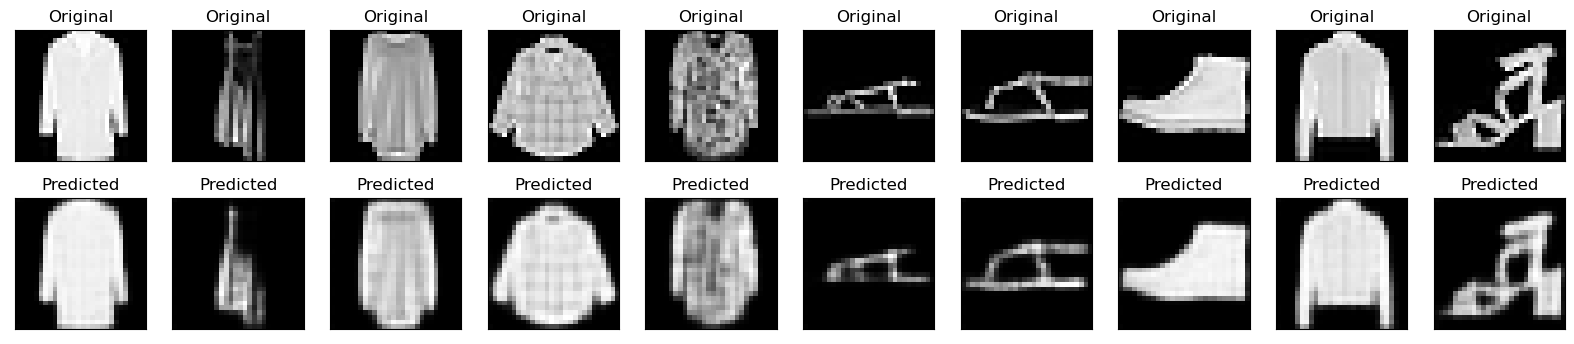

In [42]:
# Plot the first 10 predicted images

n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    # Display original images
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(np.squeeze(unsupervised_val_AnkitPatil[i]))
    plt.title("Original")
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Display predicted images
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(np.squeeze(autoencoder_predictions_AnkitPatil[i]))
    plt.title("Predicted")
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

In [43]:
#Build and perform transfer learning on a CNN with the Autoencoder
# input layer
inputs_cnn_v2_AnkitPatil = inputs_AnkitPatil

# first layer
cnn_v2_AnkitPatil = autoencoder_AnkitPatil(inputs_cnn_v2_AnkitPatil)

# flatten layer
cnn_v2_AnkitPatil = Flatten()(cnn_v2_AnkitPatil)

# fully connected layer
cnn_v2_AnkitPatil = Dense(100, activation='relu')(cnn_v2_AnkitPatil)

# output layer
cnn_v2_AnkitPatil = Dense(10, activation='softmax')(cnn_v2_AnkitPatil)

# create model
cnn_v2_AnkitPatil_model = tf.keras.models.Model(inputs=inputs_cnn_v2_AnkitPatil, outputs=cnn_v2_AnkitPatil)

# compile model
cnn_v2_AnkitPatil_model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# print model summary
cnn_v2_AnkitPatil_model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 28, 28, 1)]       0         
                                                                 
 autoencoder_AnkitPatil (Fun  (None, 28, 28, 1)        3217      
 ctional)                                                        
                                                                 
 flatten_1 (Flatten)         (None, 784)               0         
                                                                 
 dense_2 (Dense)             (None, 100)               78500     
                                                                 
 dense_3 (Dense)             (None, 10)                1010      
                                                                 
Total params: 82,727
Trainable params: 82,727
Non-trainable params: 0
_________________________________________________________

In [44]:
#Draw a diagram illustrating the structure of the neural network model
plot_model(cnn_v2_AnkitPatil_model,show_shapes=True)

You must install pydot (`pip install pydot`) and install graphviz (see instructions at https://graphviz.gitlab.io/download/) for plot_model to work.


In [45]:
# Train the model and store the results in cnn_v2_history_firstname
cnn_v2_history_AnkitPatil = cnn_v2_AnkitPatil_model.fit(x_train_AnkitPatil, y_train_AnkitPatil,
                                                epochs=10,
                                                batch_size=256,
                                                validation_data=(x_val_AnkitPatil, y_val_AnkitPatil))

Epoch 1/10
8/8 [==============================] - 2s 222ms/step - loss: 1.9384 - accuracy: 0.3256 - val_loss: 1.4090 - val_accuracy: 0.5200
Epoch 2/10
8/8 [==============================] - 1s 170ms/step - loss: 1.1732 - accuracy: 0.5794 - val_loss: 1.0266 - val_accuracy: 0.6350
Epoch 3/10
8/8 [==============================] - 1s 164ms/step - loss: 0.9238 - accuracy: 0.6511 - val_loss: 0.9134 - val_accuracy: 0.6483
Epoch 4/10
8/8 [==============================] - 1s 162ms/step - loss: 0.8213 - accuracy: 0.6989 - val_loss: 0.8138 - val_accuracy: 0.7050
Epoch 5/10
8/8 [==============================] - 2s 202ms/step - loss: 0.7473 - accuracy: 0.7344 - val_loss: 0.7984 - val_accuracy: 0.6767
Epoch 6/10
8/8 [==============================] - 1s 163ms/step - loss: 0.6923 - accuracy: 0.7556 - val_loss: 0.7178 - val_accuracy: 0.7400
Epoch 7/10
8/8 [==============================] - 1s 181ms/step - loss: 0.6793 - accuracy: 0.7639 - val_loss: 0.7518 - val_accuracy: 0.7017
Epoch 8/10
8/8 [====

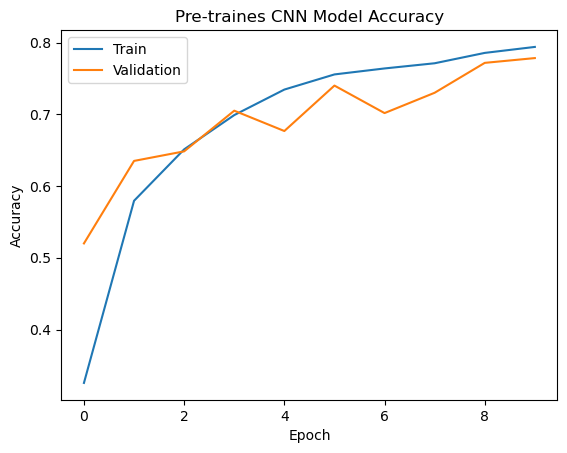

In [46]:
# Plot training & validation accuracy values
plt.plot(cnn_v2_history_AnkitPatil.history['accuracy'])
plt.plot(cnn_v2_history_AnkitPatil.history['val_accuracy'])
plt.title('Pre-traines CNN Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')
plt.show()

In [47]:
test_loss, test_acc = cnn_v2_AnkitPatil_model.evaluate(x_test_AnkitPatil, y_test_AnkitPatil, verbose=0)
print('Test accuracy:', test_acc)

Test accuracy: 0.7666666507720947


In [48]:
cnn_predictions_AnkitPatil = cnn_v2_AnkitPatil_model.predict(x_test_AnkitPatil)
y_pred = np.argmax(cnn_predictions_AnkitPatil, axis=1)
rounded_labels = np.argmax(y_test_AnkitPatil, axis=1)

19/19 [==============================] - 0s 10ms/step


In [49]:
# Confusion matrix using matplotlib
class_labels = [0,1,2,3,4,5,6,7,8,9]

#Confusion matrix
cm=confusion_matrix(y_pred,rounded_labels)

#Confusion matrix using sklearn
cm

array([[35,  0,  0,  2,  0,  0, 13,  0,  0,  0],
       [ 0, 46,  0,  1,  1,  0,  0,  0,  0,  0],
       [ 0,  0, 32,  0,  4,  0,  8,  0,  0,  0],
       [ 5,  2,  0, 55,  7,  0,  2,  0,  3,  0],
       [ 0,  1, 18,  0, 42,  0,  7,  0,  0,  0],
       [ 0,  0,  0,  0,  0, 48,  0,  1,  1,  1],
       [ 7,  1, 14,  3, 10,  0, 32,  0,  1,  0],
       [ 0,  0,  0,  0,  0,  3,  0, 47,  0,  3],
       [ 1,  0,  2,  0,  0,  1,  3,  0, 57,  0],
       [ 0,  0,  0,  0,  0,  7,  0,  7,  0, 66]], dtype=int64)

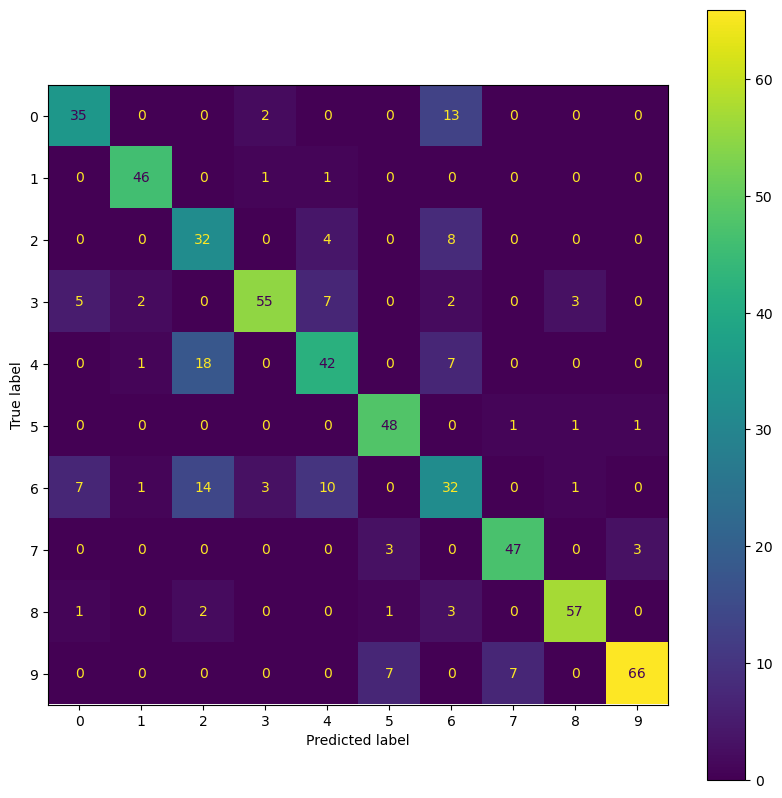

In [50]:
#Plot
disp=ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_labels)
fig, ax = plt.subplots(figsize=(10,10))
disp.plot(ax=ax);

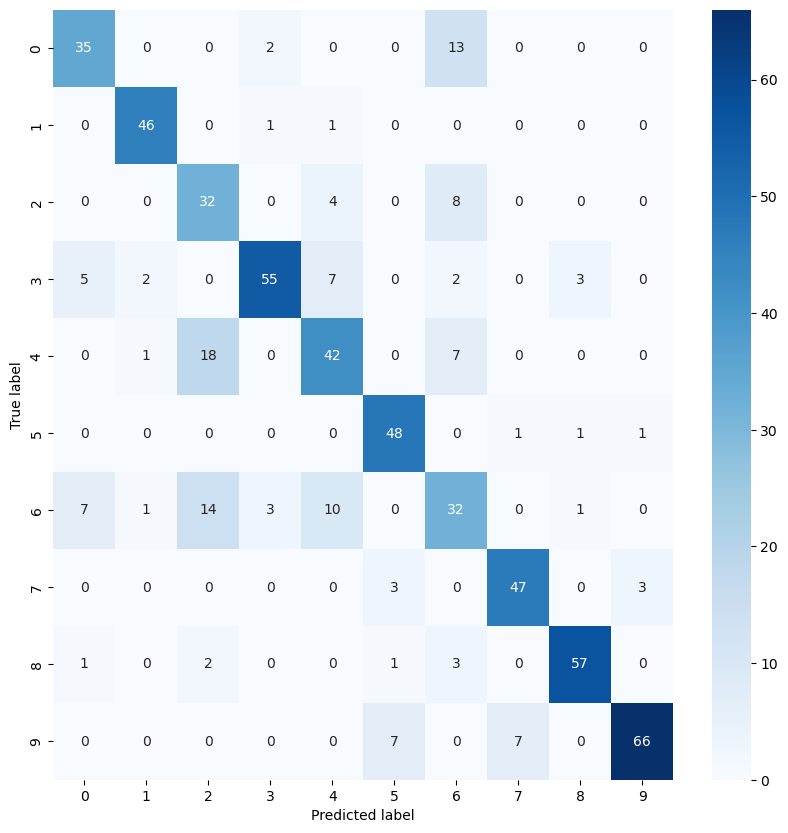

In [51]:
# Plot with Seaborn
plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, cmap='Blues', fmt='g', xticklabels=range(10), yticklabels=range(10))
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.show()

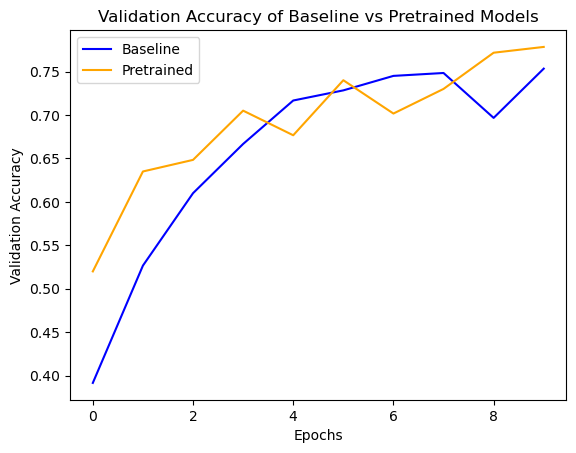

In [59]:
# Retrieve the validation accuracy from the training history of the baseline model
baseline_val_acc = cnn_v1_history_AnkitPatil.history['val_accuracy']

# Retrieve the validation accuracy from the training history of the pretrained model
pretrained_val_acc = cnn_v2_history_AnkitPatil.history['val_accuracy']

# Plot the validation accuracy of the baseline and pretrained models
plt.plot(baseline_val_acc, label='Baseline', color='blue')
plt.plot(pretrained_val_acc, label='Pretrained', color='orange')

# Add axis labels, title, and legend to the plot
plt.xlabel('Epochs')
plt.ylabel('Validation Accuracy')
plt.title('Validation Accuracy of Baseline vs Pretrained Models')
plt.legend()

# Show the plot
plt.show()